<a href="https://colab.research.google.com/github/Lu-Melo/Experimentos-Informe-6-ADA/blob/main/Informe_6_ADA_Experimentos.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Algoritmo top-dow (memoización)**

In [ ]:

import sys, time, math, random, itertools
sys.setrecursionlimit(10000)

PRIMOS = [2,3,5,7,11,13,17,19,23,29,31,37,41,43,47,53]
VMAX = 58
mascara = [0]*(VMAX+1)                    # mascara[v] = m(v)
for v in range(1, VMAX+1):
    for j, p in enumerate(PRIMOS):
        if v % p == 0:
            mascara[v] |= 1 << j

def resolver(a):
    """Devuelve (costo minimo, secuencia b, cantidad de estados (i,S) resueltos)."""
    n = len(a)
    memo = {}
    def K(i, S):                          # i = 0..n (0-indexado), S = primos usados
        if i == n:                        # caso base: K(n+1, S) = 0
            return 0
        if (i, S) in memo:                # memoización
            return memo[(i, S)]
        mejor = float("inf")
        for v in range(1, VMAX+1):        # alternativas de la decisión
            if mascara[v] & S == 0:       # v coprimo con lo ya usado
                mejor = min(mejor, abs(a[i]-v) + K(i+1, S | mascara[v]))
        memo[(i, S)] = mejor
        return mejor
    costo = K(0, 0)
    b, S = [], 0                          # reconstrucción de un b óptimo
    for i in range(n):
        for v in range(1, VMAX+1):
            if mascara[v] & S == 0 and abs(a[i]-v) + K(i+1, S | mascara[v]) == K(i, S):
                b.append(v); S |= mascara[v]; break
    return costo, b, len(memo)

def resolver_sin_memo(a):
    """Misma recurrencia pero SIN tabla. Devuelve (costo, número de llamadas)."""
    n = len(a); llamadas = [0]
    def K(i, S):
        llamadas[0] += 1
        if i == n: return 0
        mejor = float("inf")
        for v in range(1, VMAX+1):
            if mascara[v] & S == 0:
                mejor = min(mejor, abs(a[i]-v) + K(i+1, S | mascara[v]))
        return mejor
    return K(0, 0), llamadas[0]

def es_armonica(b):
    return all(math.gcd(x, y) == 1 for x, y in itertools.combinations(b, 2))
def costo_de(a, b):
    return sum(abs(x-y) for x, y in zip(a, b))

**Pruebas de Código**

In [ ]:
casos = [
    ("Ejemplo 1 del enunciado", [1,1,1,1,1]),
    ("Ejemplo 2 del enunciado", [1,6,4,2,8]),
    ("Borde: n=1, a=30",        [30]),
    ("Borde: n=1, a=1",         [1]),
    ("Ejemplo a mano",          [4,2]),
    ("Valores repetidos",       [6,6]),
    ("Tres treintas",           [30,30,30]),
    ("Todos pares",             [2,4,6,8,10,12]),
    ("n=20, todos 30",          [30]*20),
]
for nombre, a in casos:
    costo, b, _ = resolver(a)
    print(f"{nombre}\n  a = {a}\n  b = {b}\n  costo = {costo} | armónica: {es_armonica(b)} | costo recalculado: {costo_de(a,b)}\n")

Ejemplo 1 del enunciado
  a = [1, 1, 1, 1, 1]
  b = [1, 1, 1, 1, 1]
  costo = 0 | armónica: True | costo recalculado: 0

Ejemplo 2 del enunciado
  a = [1, 6, 4, 2, 8]
  b = [1, 5, 3, 1, 8]
  costo = 3 | armónica: True | costo recalculado: 3

Borde: n=1, a=30
  a = [30]
  b = [30]
  costo = 0 | armónica: True | costo recalculado: 0

Borde: n=1, a=1
  a = [1]
  b = [1]
  costo = 0 | armónica: True | costo recalculado: 0

Ejemplo a mano
  a = [4, 2]
  b = [3, 2]
  costo = 1 | armónica: True | costo recalculado: 1

Valores repetidos
  a = [6, 6]
  b = [5, 6]
  costo = 1 | armónica: True | costo recalculado: 1

Tres treintas
  a = [30, 30, 30]
  b = [29, 30, 31]
  costo = 2 | armónica: True | costo recalculado: 2

Todos pares
  a = [2, 4, 6, 8, 10, 12]
  b = [1, 3, 5, 8, 11, 13]
  costo = 5 | armónica: True | costo recalculado: 5

n=20, todos 30
  a = [30, 30, 30, 30, 30, 30, 30, 30, 30, 30, 30, 30, 30, 30, 30, 30, 30, 30, 30, 30]
  b = [1, 1, 1, 1, 11, 13, 17, 19, 23, 25, 27, 29, 31, 32, 3

**Comparación con Fuerza Bruta**

In [ ]:
def fuerza_bruta(a, tope):
    """Prueba TODAS las secuencias con b_i <= tope (sin usar la recurrencia)."""
    mejor = float("inf")
    for b in itertools.product(range(1, tope+1), repeat=len(a)):
        if es_armonica(b):
            mejor = min(mejor, costo_de(a, b))
    return mejor

random.seed(1)
iguales = 0; total = 0
for n in (1, 2, 3):
    for _ in range(15):
        a = [random.randint(1, 30) for _ in range(n)]
        total += 1
        iguales += (resolver(a)[0] == fuerza_bruta(a, 60 if n == 3 else 100))
print(f"Casos donde DP = fuerza bruta: {iguales} de {total}")

Casos donde DP = fuerza bruta: 45 de 45


**Con Memoización vs Sin Memoización**

In [ ]:
print("\n n | llamadas sin memo | estados con memo | tiempo sin memo (s) | tiempo con memo (s)")
for n in range(1, 4):
    a = [random.randint(1, 30) for _ in range(n)]
    t0 = time.perf_counter(); c1, llamadas = resolver_sin_memo(a); t1 = time.perf_counter() - t0
    t0 = time.perf_counter(); c2, _, estados = resolver(a);        t2 = time.perf_counter() - t0
    assert c1 == c2
    print(f"{n:2d} | {llamadas:17,d} | {estados:16,d} | {t1:19.4f} | {t2:.4f}")


 n | llamadas sin memo | estados con memo | tiempo sin memo (s) | tiempo con memo (s)
 1 |                59 |                1 |              0.0000 | 0.0000
 2 |             2,114 |               37 |              0.0008 | 0.0005
 3 |            57,132 |              408 |              0.0255 | 0.0051


**Tiempo vs Tamaño de la Entrada**

n= 1  estados=       1  tiempo=0.000 s  tiempo/estado=38.9 µs
n= 2  estados=      37  tiempo=0.001 s  tiempo/estado=13.6 µs
n= 3  estados=     408  tiempo=0.006 s  tiempo/estado=13.5 µs
n= 4  estados=   2,402  tiempo=0.033 s  tiempo/estado=13.6 µs
n= 5  estados=   9,237  tiempo=0.124 s  tiempo/estado=13.4 µs
n= 6  estados=  25,821  tiempo=0.358 s  tiempo/estado=13.9 µs
n= 7  estados=  56,334  tiempo=0.796 s  tiempo/estado=14.1 µs
n= 8  estados= 101,340  tiempo=1.942 s  tiempo/estado=19.2 µs
n= 9  estados= 157,432  tiempo=2.570 s  tiempo/estado=16.3 µs
n=10  estados= 219,720  tiempo=3.561 s  tiempo/estado=16.2 µs


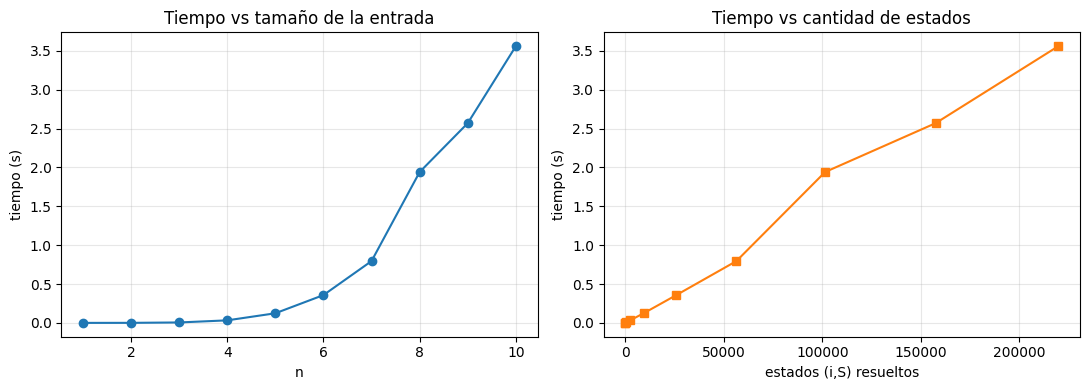

In [ ]:
import matplotlib.pyplot as plt
ns, tiempos, estados_l = [], [], []
for n in range(1, 11):
    ts = []
    for _ in range(3):
        a = [random.randint(1, 30) for _ in range(n)]
        t0 = time.perf_counter(); _, _, est = resolver(a); ts.append(time.perf_counter() - t0)
    ns.append(n); tiempos.append(sorted(ts)[1]); estados_l.append(est)
    print(f"n={n:2d}  estados={est:8,d}  tiempo={tiempos[-1]:.3f} s  tiempo/estado={tiempos[-1]/est*1e6:.1f} µs")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(ns, tiempos, "o-"); ax[0].set_xlabel("n"); ax[0].set_ylabel("tiempo (s)"); ax[0].set_title("Tiempo vs tamaño de la entrada"); ax[0].grid(alpha=.3)
ax[1].plot(estados_l, tiempos, "s-", color="C1"); ax[1].set_xlabel("estados (i,S) resueltos"); ax[1].set_ylabel("tiempo (s)"); ax[1].set_title("Tiempo vs cantidad de estados"); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.savefig("tiempos_python.png", dpi=150); plt.show()